# Pruning vs INT8 Quantization on Fashion-MNIST

**Research question.** For one fixed Fashion-MNIST classifier, which gives the better measured trade-off between accuracy, saved file size and CPU latency: unstructured magnitude pruning or dynamic INT8 quantization? And do the zeros created by pruning turn into a smaller file or faster inference?

| Item | Choice |
|---|---|
| Data | Fashion-MNIST, official 60,000 train / 10,000 test. Train split 90/10 into train/validation per seed |
| Model | MLP 784 → 256 → 128 → 10 (235,146 parameters) |
| Training | Adam, lr 0.001, batch 128, 10 epochs, checkpoint with the lowest validation loss |
| Variants | FP32 baseline; global L1 pruning at 30/50/70/90%; dynamic INT8; 50% pruning then INT8 |
| Seeds | 42, 123, 2026 (paired: every variant comes from its own seed's baseline) |
| Metrics | Accuracy, macro F1, per-class F1, confusion matrix, measured sparsity, saved bytes, CPU latency p50/p95/IQR |

The full protocol is in `docs/protocol.md`. Reusable code lives in `src/`; this notebook runs the study and shows the results. All settings come from `src/config.py`.

**How to run:** select the project `.venv` kernel and run all cells from the top (about 3–4 minutes on a laptop CPU). Everything is written under `outputs/`.

## 1. Environment

Imports the project modules and records software versions, CPU and the INT8 engine to `outputs/setup.json`. Latency numbers are only meaningful together with this record.

In [1]:
import json
import os
import platform
import subprocess
import sys
from pathlib import Path

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torchvision

from src import benchmark, compress, config, data, evaluate, plotresults, train
from src.model import MLP, countparams

pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)
config.outdir.mkdir(exist_ok=True)
metricsdir = config.outdir / "metrics"
figdir = config.outdir / "figures"
metricsdir.mkdir(exist_ok=True)
figdir.mkdir(exist_ok=True)

In [2]:
def cpuname():
    if platform.system() == "Darwin":
        return subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"],
                              capture_output=True, text=True).stdout.strip()
    return platform.processor() or platform.machine()


device = "cuda" if torch.cuda.is_available() else "cpu"
engine = compress.chooseengine()
setup = {
    "python": platform.python_version(),
    "pytorch": torch.__version__,
    "torchvision": torchvision.__version__,
    "scikitlearn": sklearn.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "os": platform.platform(),
    "cpu": cpuname(),
    "logicalcpus": os.cpu_count(),
    "trainingdevice": device,
    "quantizedengine": engine,
    "supportedengines": torch.backends.quantized.supported_engines,
    "benchmarkthreads": config.benchthreads,
}
(config.outdir / "setup.json").write_text(json.dumps(setup, indent=2))
print(json.dumps(setup, indent=2))

{
  "python": "3.11.15",
  "pytorch": "2.15.0",
  "torchvision": "0.29.2",
  "scikitlearn": "1.9.1",
  "numpy": "2.4.6",
  "pandas": "3.1.1",
  "matplotlib": "3.11.2",
  "os": "macOS-26.3.1-arm64-arm-64bit",
  "cpu": "Apple M2",
  "logicalcpus": 8,
  "trainingdevice": "cpu",
  "quantizedengine": "qnnpack",
  "supportedengines": [
    "qnnpack"
  ],
  "benchmarkthreads": 1
}


## 2. Data

Loads the official partitions (pixels scaled to [0, 1] by `ToTensor`), checks counts, class balance and pixel range, and shows one example per class. The test set is only used for the final evaluation in Section 6.

In [3]:
trainset, testset = data.loaddatasets()
classes = trainset.classes
traincounts = np.bincount(trainset.targets.numpy(), minlength=10)
testcounts = np.bincount(testset.targets.numpy(), minlength=10)
firstimage = trainset[0][0]
summary = {
    "train": len(trainset),
    "test": len(testset),
    "imageshape": list(firstimage.shape),
    "pixelrange": [float(firstimage.min()), float(firstimage.max())],
    "classes": classes,
    "traincounts": traincounts.tolist(),
    "testcounts": testcounts.tolist(),
}
(config.outdir / "dataset-summary.json").write_text(json.dumps(summary, indent=2))
print("Train / test examples:", len(trainset), "/", len(testset))
print("Image shape:", tuple(firstimage.shape), " pixel range:", summary["pixelrange"])
pd.DataFrame({"class": classes, "train": traincounts, "test": testcounts})

Train / test examples: 60000 / 10000
Image shape: (1, 28, 28)  pixel range: [0.0, 1.0]


,class,train,test
0,T-shirt/top,6000,1000
1,Trouser,6000,1000
2,Pullover,6000,1000
3,Dress,6000,1000
4,Coat,6000,1000
5,Sandal,6000,1000
6,Shirt,6000,1000
7,Sneaker,6000,1000
8,Bag,6000,1000
9,Ankle boot,6000,1000


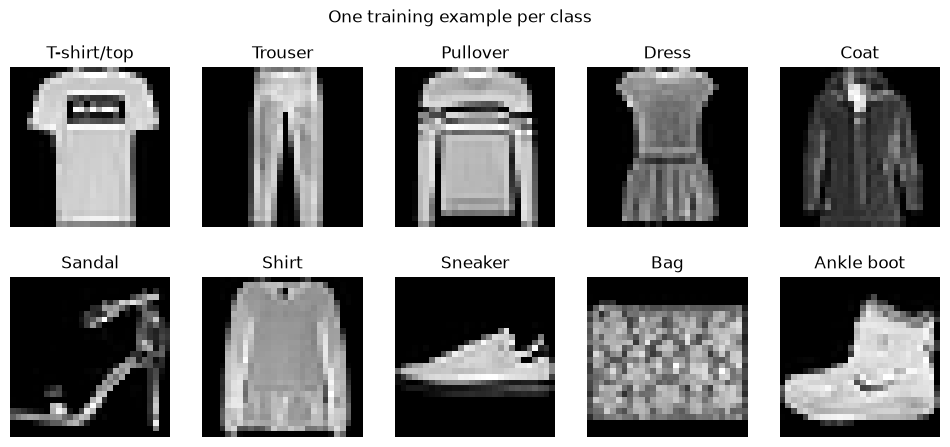

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
firstindex = {}
for index, label in enumerate(trainset.targets.tolist()):
    firstindex.setdefault(label, index)
for label, ax in enumerate(axes.flat):
    ax.imshow(trainset[firstindex[label]][0].squeeze(), cmap="gray")
    ax.set_title(classes[label])
    ax.axis("off")
fig.suptitle("One training example per class")
plotresults.save(fig, figdir / "samples.png")
plt.show()

## 3. Model check

One forward pass on a batch to confirm the output shape and the parameter count.

In [5]:
checkmodel = MLP()
images = torch.stack([trainset[i][0] for i in range(8)])
print(checkmodel)
print("Output shape:", tuple(checkmodel(images).shape))
print("Parameters:", f"{countparams(checkmodel):,}")

MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Output shape: (8, 10)
Parameters: 235,146


## 4. Frozen protocol settings

Saved with the run so the results can be traced back to the exact settings.

In [6]:
(config.outdir / "runs").mkdir(exist_ok=True)
(config.outdir / "runs" / "config.json").write_text(json.dumps(config.settings(), indent=2))
config.settings()

{'seeds': [42, 123, 2026],
 'valfraction': 0.1,
 'batchsize': 128,
 'learningrate': 0.001,
 'epochs': 10,
 'hidden': [256, 128],
 'optimizer': 'Adam',
 'loss': 'CrossEntropyLoss',
 'checkpointrule': 'lowest validation loss',
 'prunelevels': [0.3, 0.5, 0.7, 0.9],
 'combinedlevel': 0.5,
 'tolerance': 1.0,
 'benchthreads': 1,
 'benchbatches': [1, 64],
 'warmup': 30,
 'repeats': 200}

## 5. Train one FP32 baseline per seed

Each seed gets its own train/validation split, its own shuffling order and its own initial weights. The checkpoint kept is the epoch with the **lowest validation loss**. The split indices, training history and chosen epoch are saved under `outputs/runs/seed<N>/`.

In [7]:
baselines = {}
bestepochs = {}
historyrows = []
for seed in config.seeds:
    trainloader, valloader, testloader, split = data.makeloaders(trainset, testset, seed)
    assert not set(split["train"]) & set(split["validation"])
    rundir = config.outdir / "runs" / f"seed{seed}"
    rundir.mkdir(parents=True, exist_ok=True)
    (rundir / "split.json").write_text(json.dumps(split))
    baseline, history, bestepoch = train.trainbaseline(seed, trainloader, valloader, device)
    baselines[seed] = baseline
    bestepochs[seed] = bestepoch
    historyrows.extend(history)
    pd.DataFrame(history).to_csv(rundir / "history.csv", index=False)
    chosen = history[bestepoch - 1]
    print(f"seed {seed}: chosen epoch {bestepoch}  val loss {chosen['valloss']:.4f}  "
          f"val acc {chosen['valacc']:.4f}")
history = pd.DataFrame(historyrows)
history.to_csv(metricsdir / "history.csv", index=False)

seed 42: chosen epoch 9  val loss 0.3058  val acc 0.8918


seed 123: chosen epoch 8  val loss 0.3032  val acc 0.8867


seed 2026: chosen epoch 6  val loss 0.3044  val acc 0.8928


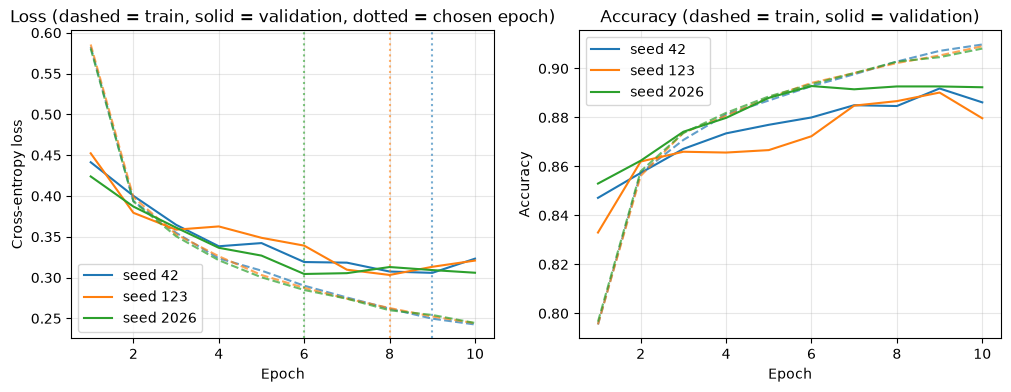

In [8]:
plotresults.learningcurves(history, bestepochs, figdir / "learning-curves.png")
plt.show()

## 6. Build, save, reload and evaluate every variant

For each seed, all variants are derived independently from that seed's baseline. Each one is saved as an inference-only state dictionary named `model.pt` in its own folder, so every file has the same internal archive name and sizes are comparable. The **reloaded file** is what gets evaluated, and its predictions are checked against the in-memory model.

In [9]:
resultrows, perclassrows, layerrows, comparerows = [], [], [], []
predictions = {}
confusions = {}
testloader = data.makeloaders(trainset, testset, config.seeds[0])[2]
totalparams = countparams(MLP())

for seed in config.seeds:
    variants = compress.makevariants(baselines[seed])
    seedpreds = {}
    for name, variant in variants.items():
        path = config.outdir / "checkpoints" / f"seed{seed}" / name / "model.pt"
        size = compress.saveartifact(variant, path)
        reloaded = compress.loadartifact(name, path)
        pred, labels = evaluate.predict(reloaded, testloader)
        assert (pred == evaluate.predict(variant, testloader)[0]).all(), f"reload changed {name}"
        seedpreds[name] = pred
        overall, layers = compress.sparsity(reloaded)
        target = float(name[6:8]) / 100 if name.startswith("pruned") else 0.0
        resultrows.append({"seed": seed, "variant": name, "target": target, "sparsity": overall,
                           **evaluate.scores(pred, labels), "bytes": size,
                           "bitsperparam": size * 8 / totalparams})
        for row in evaluate.perclass(pred, labels, classes):
            perclassrows.append({"seed": seed, "variant": name, **row})
        for row in layers:
            layerrows.append({"seed": seed, "variant": name, **row})
        confusions[(seed, name)] = evaluate.confusion(pred, labels, classes)
        if name != "fp32":
            comparerows.append({"seed": seed, "variant": name,
                                **evaluate.comparepredictions(seedpreds["fp32"], pred, labels)})
    predictions[seed] = pd.DataFrame({"label": labels, **seedpreds})
    print(f"seed {seed}: saved, reloaded and evaluated {len(variants)} variants")

seed 42: saved, reloaded and evaluated 7 variants


seed 123: saved, reloaded and evaluated 7 variants


seed 2026: saved, reloaded and evaluated 7 variants


In [10]:
results = pd.DataFrame(resultrows)
base = results[results.variant == "fp32"].set_index("seed")
results["deltaaccpp"] = (results.accuracy - results.seed.map(base.accuracy)) * 100
results["deltaf1pp"] = (results.macrof1 - results.seed.map(base.macrof1)) * 100
results["ratio"] = results.seed.map(base.bytes) / results.bytes

results.to_csv(metricsdir / "results.csv", index=False)
perclass = pd.DataFrame(perclassrows)
perclass.to_csv(metricsdir / "perclass.csv", index=False)
layersparsity = pd.DataFrame(layerrows)
layersparsity.to_csv(metricsdir / "layersparsity.csv", index=False)
comparisons = pd.DataFrame(comparerows)
comparisons.to_csv(metricsdir / "comparisons.csv", index=False)
(metricsdir / "predictions").mkdir(exist_ok=True)
(metricsdir / "confusion").mkdir(exist_ok=True)
for seed, table in predictions.items():
    table.rename_axis("index").to_csv(metricsdir / "predictions" / f"seed{seed}.csv")
for (seed, name), matrix in confusions.items():
    pd.DataFrame(matrix, index=classes, columns=classes).to_csv(
        metricsdir / "confusion" / f"seed{seed}-{name}.csv")
results.round(4)

,seed,variant,target,sparsity,accuracy,macrof1,bytes,bitsperparam,deltaaccpp,deltaf1pp,ratio
0,42,fp32,0.0,0.0000,0.8858,0.8849,943357,32.0943,0.00,0.0000,1.0000
1,42,pruned30,0.3,0.3000,0.8862,0.8855,943357,32.0943,0.04,0.0602,1.0000
2,42,pruned50,0.5,0.5000,0.8745,0.8757,943357,32.0943,-1.13,-0.9190,1.0000
3,42,pruned70,0.7,0.7000,0.8109,0.8176,943357,32.0943,-7.49,-6.7298,1.0000
4,42,pruned90,0.9,0.9000,0.3564,0.2938,943357,32.0943,-52.94,-59.1130,1.0000
5,42,int8,0.0,0.0379,0.8853,0.8843,240987,8.1987,-0.05,-0.0601,3.9146
6,42,pruned50int8,0.5,0.5000,0.8745,0.8756,240987,8.1987,-1.13,-0.9289,3.9146
7,123,fp32,0.0,0.0000,0.8795,0.8786,943357,32.0943,0.00,0.0000,1.0000
8,123,pruned30,0.3,0.3000,0.8782,0.8772,943357,32.0943,-0.13,-0.1461,1.0000
9,123,pruned50,0.5,0.5000,0.8746,0.8742,943357,32.0943,-0.49,-0.4481,1.0000


## 7. CPU latency benchmark

Every saved artifact is reloaded and timed on the CPU with the same 64 real test images. Settings: `torch.inference_mode()`, 1 thread, 30 warm-up passes, 200 timed passes for batch sizes 1 and 64. Only the forward pass is inside the timer. Every raw timing is saved to `latency-raw.csv`.

In [11]:
benchimages = torch.stack([testset[i][0] for i in range(max(config.benchbatches))])
rawrows = []
for seed in config.seeds:
    for name in compress.variantnames():
        path = config.outdir / "checkpoints" / f"seed{seed}" / name / "model.pt"
        rawrows.extend(benchmark.measure(name, seed, compress.loadartifact(name, path), benchimages))
raw = pd.DataFrame(rawrows)
raw.to_csv(metricsdir / "latency-raw.csv", index=False)

latencyrows = []
for (seed, name, batchsize), group in raw.groupby(["seed", "variant", "batchsize"], sort=False):
    latencyrows.append({"seed": seed, "variant": name, "batchsize": batchsize,
                        **benchmark.summarize(group.latencyms)})
latency = pd.DataFrame(latencyrows)
latency.to_csv(metricsdir / "latency.csv", index=False)
latency.groupby(["variant", "batchsize"], sort=False)[["p50ms", "p95ms", "iqrms"]].mean().unstack()

p50ms           p95ms           iqrms        
batchsize         1       64      1       64      1       64
variant                                                     
fp32          0.0228  0.0690  0.0248  0.0729  0.0015  0.0003
pruned30      0.0228  0.0691  0.0249  0.0710  0.0016  0.0004
pruned50      0.0228  0.0692  0.0248  0.0712  0.0014  0.0004
pruned70      0.0228  0.0693  0.0249  0.0755  0.0016  0.0005
pruned90      0.0227  0.0692  0.0246  0.0718  0.0014  0.0004
int8          0.1143  0.2386  0.1239  0.2671  0.0077  0.0114
pruned50int8  0.1141  0.2390  0.1235  0.2624  0.0075  0.0098

## 8. Summary across seeds

Mean and standard deviation (SD) over the paired seeds. `deltaaccpp` is the change in accuracy from the same seed's FP32 baseline, in percentage points. Latency columns are the mean over seeds of each run's median (p50) and p95.

In [12]:
order = compress.variantnames()
grouped = results.groupby("variant")
summary = grouped[["target", "sparsity", "accuracy", "macrof1", "deltaaccpp", "deltaf1pp",
                   "bytes", "bitsperparam", "ratio"]].mean().loc[order]
summary.insert(3, "accuracysd", grouped.accuracy.std().loc[order])
summary.insert(6, "deltaaccppsd", grouped.deltaaccpp.std().loc[order])
for batchsize in config.benchbatches:
    rows = latency[latency.batchsize == batchsize].groupby("variant")
    summary[f"p50ms{batchsize}"] = rows.p50ms.mean().loc[order]
    summary[f"p95ms{batchsize}"] = rows.p95ms.mean().loc[order]
summary["seeds"] = grouped.seed.nunique().loc[order]
summary.to_csv(metricsdir / "summary.csv")
summary.round(4)

,target,sparsity,accuracy,accuracysd,macrof1,deltaaccpp,deltaaccppsd,deltaf1pp,bytes,bitsperparam,ratio,p50ms1,p95ms1,p50ms64,p95ms64,seeds
variant,,,,,,,,,,,,,,,,
fp32,0.0,0.0000,0.8819,0.0034,0.8811,0.0000,0.0000,0.0000,943357.0,32.0943,1.0000,0.0228,0.0248,0.0690,0.0729,3
pruned30,0.3,0.3000,0.8821,0.0040,0.8813,0.0133,0.1320,0.0224,943357.0,32.0943,1.0000,0.0228,0.0249,0.0691,0.0710,3
pruned50,0.5,0.5000,0.8748,0.0004,0.8752,-0.7167,0.3585,-0.5878,943357.0,32.0943,1.0000,0.0228,0.0248,0.0692,0.0712,3
pruned70,0.7,0.7000,0.8182,0.0171,0.8219,-6.3767,1.9024,-5.9155,943357.0,32.0943,1.0000,0.0228,0.0249,0.0693,0.0755,3
pruned90,0.9,0.9000,0.4044,0.0562,0.3544,-47.7500,5.8376,-52.6674,943357.0,32.0943,1.0000,0.0227,0.0246,0.0692,0.0718,3
int8,0.0,0.0414,0.8822,0.0028,0.8813,0.0267,0.0681,0.0225,240987.0,8.1987,3.9146,0.1143,0.1239,0.2386,0.2671,3
pruned50int8,0.5,0.5000,0.8749,0.0006,0.8753,-0.7067,0.3814,-0.5791,240987.0,8.1987,3.9146,0.1141,0.1235,0.2390,0.2624,3


## 9. Pre-registered decision rule

From `docs/protocol.md`: among variants whose **mean accuracy is within 1 percentage point** of the paired FP32 baseline, choose the one with the **smallest saved artifact**, then compare latency. Target sparsity is not treated as a size budget.

In [13]:
eligible = summary[summary.deltaaccpp >= -config.tolerance].sort_values("bytes")
print(f"Variants within {config.tolerance:g} pp of FP32 (smallest file first):")
display(eligible[["accuracy", "deltaaccpp", "bytes", "ratio", "p50ms1", "p50ms64"]].round(4))
choice = eligible.index[0]
print(f"Selected: {choice}  ({summary.loc[choice, 'bytes']:,.0f} bytes, "
      f"{summary.loc[choice, 'ratio']:.2f}x smaller than FP32, "
      f"accuracy change {summary.loc[choice, 'deltaaccpp']:+.2f} pp)")

Variants within 1 pp of FP32 (smallest file first):


,accuracy,deltaaccpp,bytes,ratio,p50ms1,p50ms64
variant,,,,,,
int8,0.8822,0.0267,240987.0,3.9146,0.1143,0.2386
pruned50int8,0.8749,-0.7067,240987.0,3.9146,0.1141,0.2390
fp32,0.8819,0.0000,943357.0,1.0000,0.0228,0.0690
pruned30,0.8821,0.0133,943357.0,1.0000,0.0228,0.0691
pruned50,0.8748,-0.7167,943357.0,1.0000,0.0228,0.0692


Selected: int8  (240,987 bytes, 3.91x smaller than FP32, accuracy change +0.03 pp)


## 10. Trade-off figures

All figures are drawn from the saved tables above.

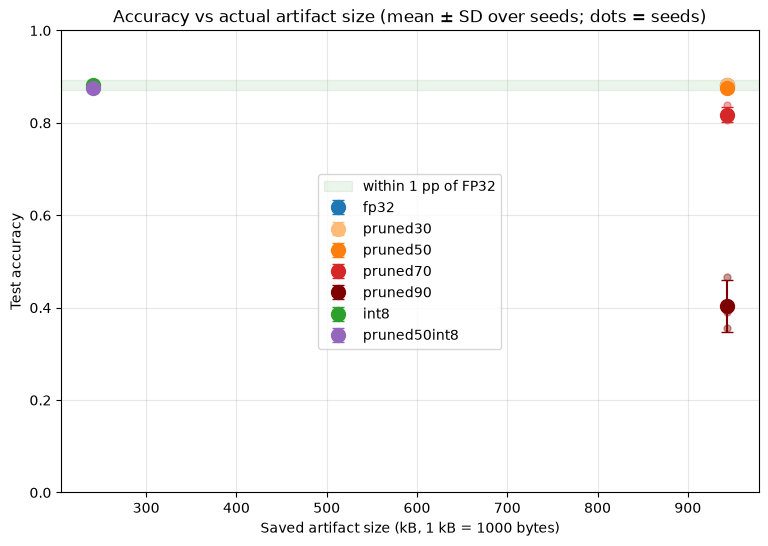

In [14]:
plotresults.qualitysize(results, summary, config.tolerance, figdir / "quality-size.png")
plt.show()

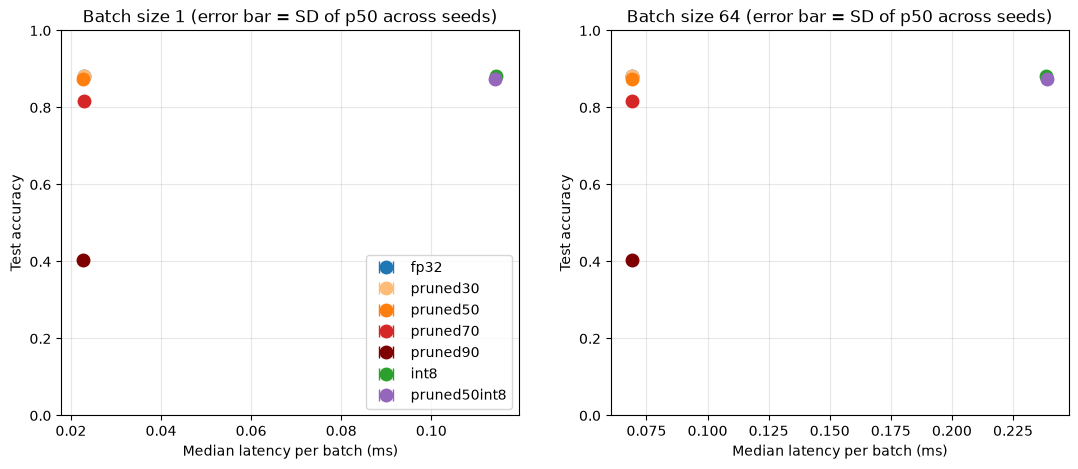

In [15]:
plotresults.qualitylatency(latency, summary, figdir / "quality-latency.png")
plt.show()

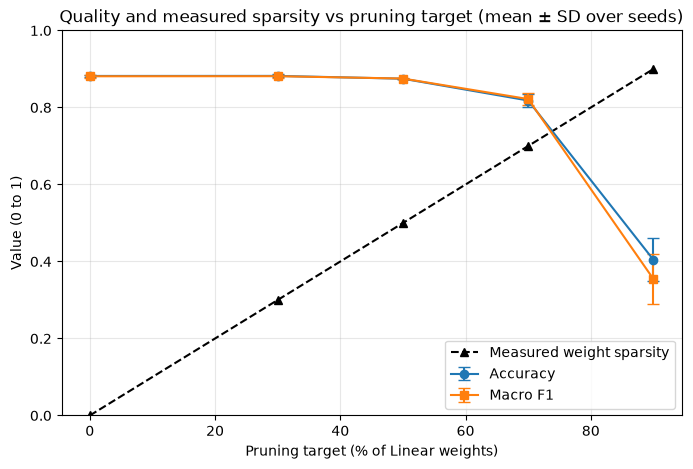

In [16]:
plotresults.pruningcurve(results, config.prunelevels, figdir / "pruning-curve.png")
plt.show()

## 11. Where the sparsity goes

Global pruning uses one magnitude cut-off for all layers, so layers with smaller weights lose more of them. The histogram shows the baseline weights for seed 42 with each pruning level's cut-off. `deadunits` counts neurons whose incoming weights are all zero.

Hand-computed 90% cut-off: 0.12209  weights at or below it: 211277  mismatches with PyTorch pruning: 0


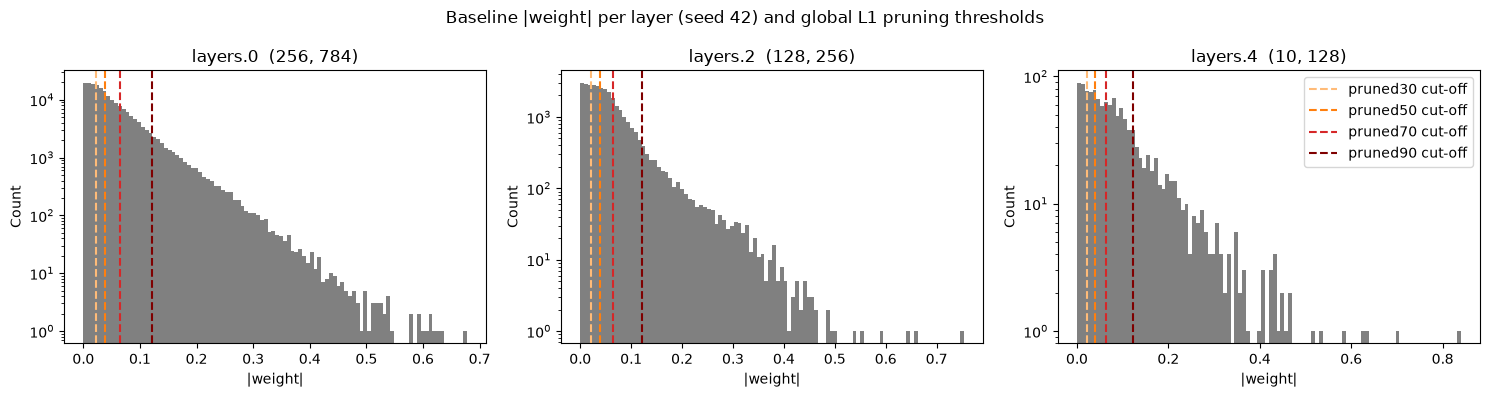

In [17]:
layers = compress.layerweights(baselines[config.seeds[0]])
allweights = torch.cat([weight.abs().flatten() for _, weight in layers])
thresholds = {}
for level in config.prunelevels:
    cutoff = round(level * allweights.numel())
    thresholds[f"pruned{round(level * 100)}"] = allweights.kthvalue(cutoff).values.item()
pruned90 = compress.prunemodel(baselines[config.seeds[0]], 0.9)
handmask = torch.cat([(weight.abs() <= thresholds["pruned90"]).flatten() for _, weight in layers])
torchmask = torch.cat([(weight == 0).flatten() for _, weight in compress.layerweights(pruned90)])
print("Hand-computed 90% cut-off:", round(thresholds["pruned90"], 5),
      " weights at or below it:", int(handmask.sum()),
      " mismatches with PyTorch pruning:", int((handmask != torchmask).sum()))
plotresults.weighthist(layers, thresholds, figdir / "weight-distribution.png")
plt.show()

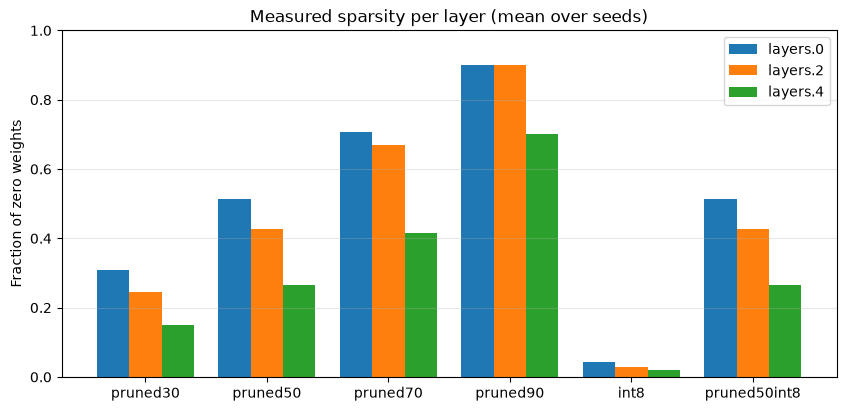

sparsity                   deadunits                  
layer        layers.0 layers.2 layers.4  layers.0 layers.2 layers.4
variant                                                            
fp32           0.0000   0.0000   0.0000    0.0000      0.0      0.0
pruned30       0.3098   0.2459   0.1500    0.0000      0.0      0.0
pruned50       0.5135   0.4268   0.2643    0.0000      0.0      0.0
pruned70       0.7070   0.6684   0.4167   28.3333      0.0      0.0
pruned90       0.9010   0.9015   0.7018   29.6667     13.0      0.0
int8           0.0436   0.0288   0.0198    0.0000      0.0      0.0
pruned50int8   0.5135   0.4268   0.2643    0.0000      0.0      0.0

In [18]:
plotresults.layersparsityplot(layersparsity, figdir / "layer-sparsity.png")
plt.show()
layersparsity.groupby(["variant", "layer"], sort=False)[["sparsity", "deadunits"]].mean().unstack().loc[order]

## 12. Class-level and example-level failure analysis

Which classes lose the most F1, how many test examples change between FP32 and each variant, and which examples FP32 gets right but a compressed model gets wrong. Examples are taken in test-index order (not hand-picked), and all IDs are saved to `outputs/metrics/failures-seed42.csv`.

In [19]:
fp32class = perclass[perclass.variant == "fp32"].set_index(["seed", "class"]).f1
perclass["deltaf1pp"] = (perclass.f1 - perclass.set_index(["seed", "class"]).index.map(fp32class)) * 100
classdrop = perclass.groupby(["variant", "class"], sort=False).deltaf1pp.mean().unstack().loc[order[1:]]
classdrop.round(2)

class,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
variant,,,,,,,,,,
pruned30,-0.11,-0.00,-0.15,0.10,-0.31,0.07,0.47,0.14,-0.12,0.14
pruned50,-0.66,0.06,-1.15,0.11,-1.73,-0.81,-0.15,-0.71,-0.49,-0.33
pruned70,-5.52,-0.91,-6.68,-2.32,-21.03,-4.73,-10.48,-3.16,-2.12,-2.19
pruned90,-49.85,-60.08,-26.05,-31.40,-77.74,-51.14,-23.37,-57.90,-53.63,-95.51
int8,-0.00,-0.03,0.13,0.05,0.19,-0.02,-0.03,-0.02,-0.03,-0.02
pruned50int8,-0.68,0.03,-1.04,0.07,-1.71,-0.79,-0.21,-0.73,-0.42,-0.30


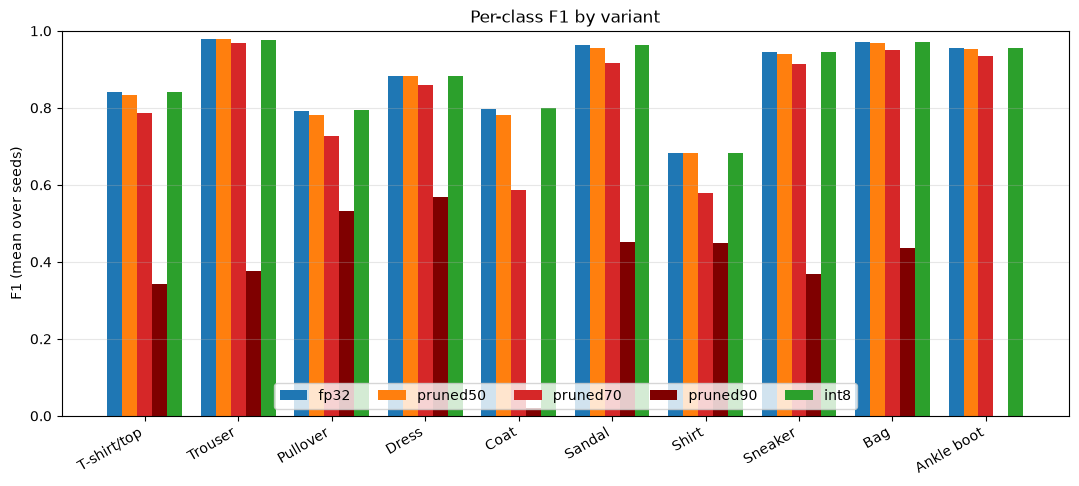

,newerrors,fixed,bothwrong,disagree
variant,,,,
pruned30,43.6667,45.0000,1135.6667,102.6667
pruned50,189.3333,117.6667,1063.0000,356.6667
pruned70,898.0000,260.3333,920.3333,1332.6667
pruned90,5110.0000,335.0000,845.6667,5884.0000
int8,9.3333,12.0000,1168.6667,25.0000
pruned50int8,188.6667,118.0000,1062.6667,357.3333


In [20]:
plotresults.perclassf1(perclass, ["fp32", "pruned50", "pruned70", "pruned90", "int8"],
                       figdir / "perclass-f1.png")
plt.show()
comparisons.groupby("variant", sort=False)[["newerrors", "fixed", "bothwrong", "disagree"]].mean()

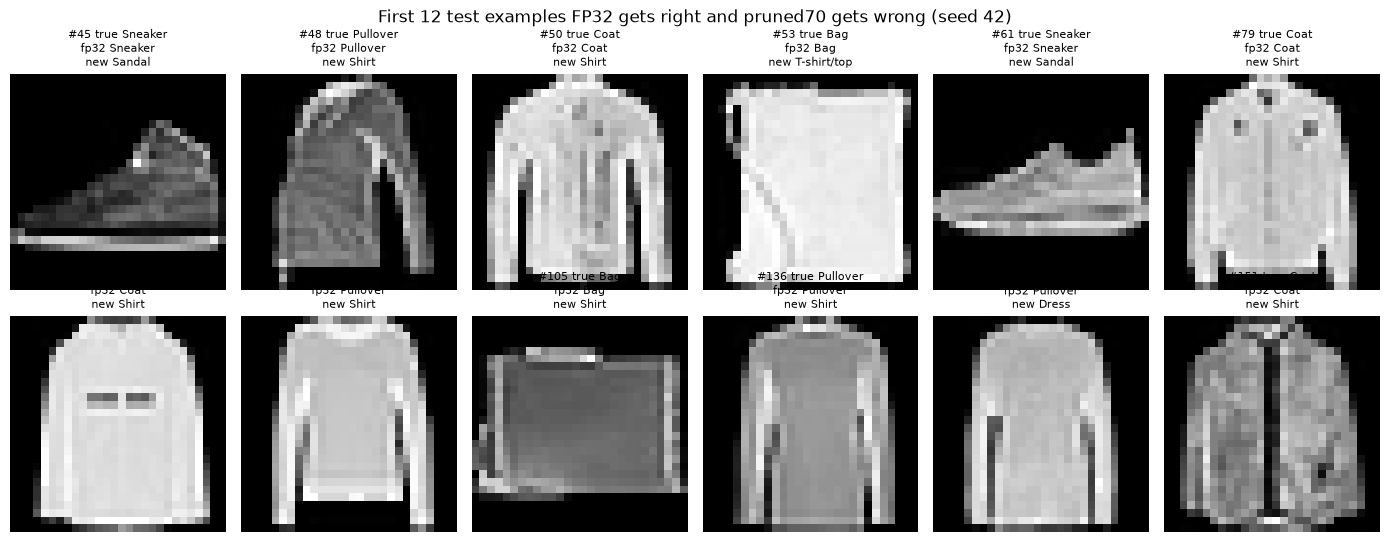

In [21]:
seed = config.seeds[0]
table = predictions[seed]
failurerows = []
for name in order[1:]:
    mask = (table.fp32 == table.label) & (table[name] != table.label)
    for index in table.index[mask]:
        failurerows.append({"variant": name, "index": index, "label": table.label[index],
                            "fp32": table.fp32[index], "variantpred": table[name][index]})
failures = pd.DataFrame(failurerows)
failures.to_csv(metricsdir / f"failures-seed{seed}.csv", index=False)
first = failures[failures.variant == "pruned70"].head(12)
plotresults.examplegrid(testset, first, classes,
                        "First 12 test examples FP32 gets right and pruned70 gets wrong (seed 42)",
                        figdir / "failures-pruned70.png")
plt.show()

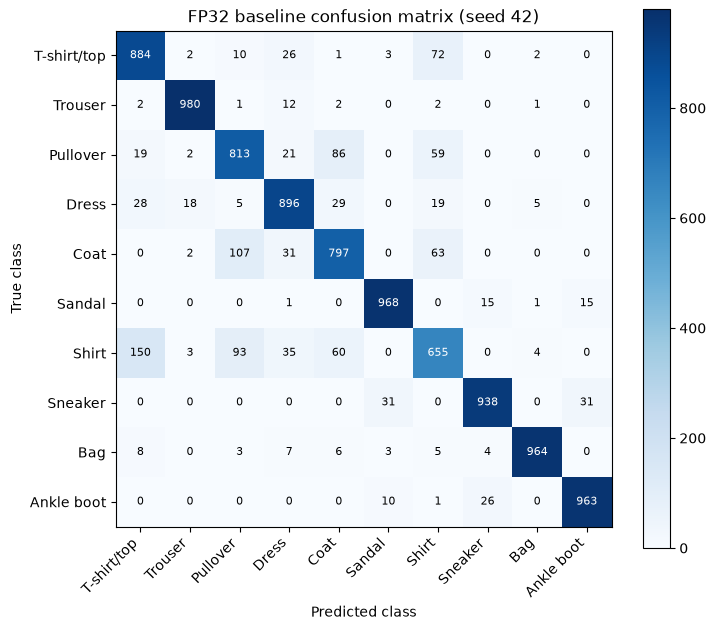

In [22]:
plotresults.confusionplot(confusions[(seed, "fp32")], classes, "FP32 baseline confusion matrix (seed 42)",
                          figdir / "confusion-fp32.png")
plt.show()

## 13. Why 90% pruning collapses

At 90% sparsity the model does not just lose a little accuracy everywhere; it falls back to predicting a few classes for most images. This compares predicted-class counts with the true count (1,000 per class), and lists mean per-class recall across seeds.

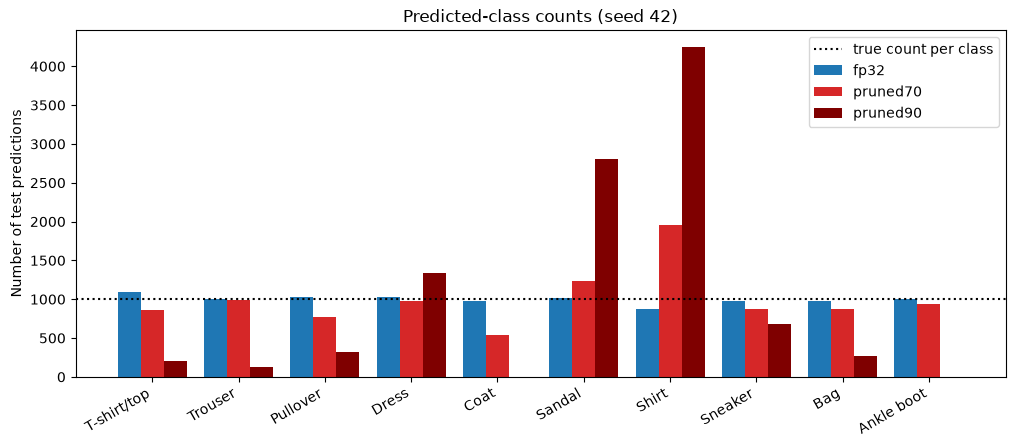

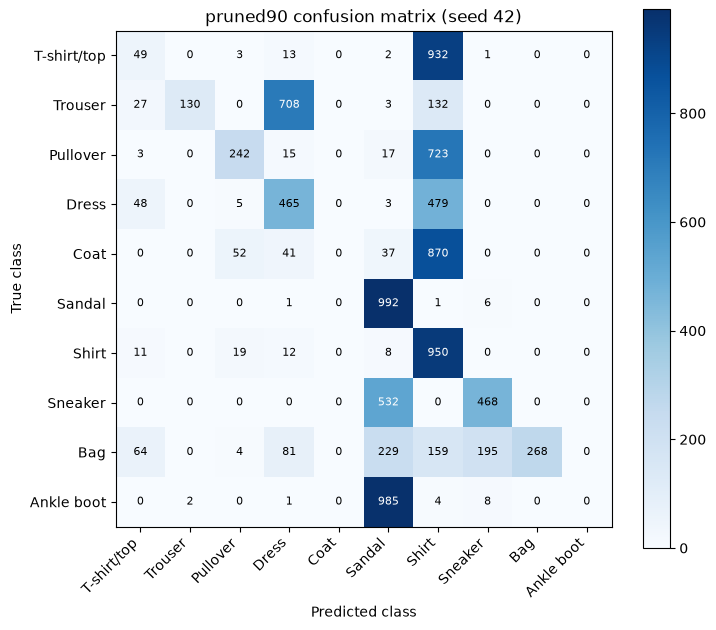

variant,fp32,pruned70,pruned90
class,,,
T-shirt/top,0.869,0.767,0.418
Trouser,0.970,0.954,0.239
Pullover,0.796,0.662,0.449
Dress,0.907,0.851,0.534
Coat,0.802,0.457,0.010
Sandal,0.954,0.986,0.996
Shirt,0.642,0.800,0.815
Sneaker,0.959,0.897,0.294
Bag,0.967,0.917,0.288


In [23]:
counts = {name: np.bincount(table[name], minlength=10) for name in ["fp32", "pruned70", "pruned90"]}
plotresults.predictionhist(counts, classes, figdir / "prediction-collapse.png")
plt.show()
plotresults.confusionplot(confusions[(seed, "pruned90")], classes, "pruned90 confusion matrix (seed 42)",
                          figdir / "confusion-pruned90.png")
plt.show()
recall = perclass[perclass.variant.isin(["fp32", "pruned70", "pruned90"])]
recall.groupby(["class", "variant"], sort=False).recall.mean().unstack().round(3)

In [24]:
results[results.variant == "pruned90"][["seed", "sparsity", "accuracy", "macrof1", "deltaaccpp"]].round(4)

,seed,sparsity,accuracy,macrof1,deltaaccpp
4,42,0.9,0.3564,0.2938,-52.94
11,123,0.9,0.3907,0.3463,-48.88
18,2026,0.9,0.4662,0.4232,-41.43


## 14. Key findings

All numbers are means over 3 paired seeds (42, 123, 2026) from `outputs/metrics/summary.csv`, measured on an Apple M2 CPU with the `qnnpack` INT8 engine and 1 thread. Accuracy and file sizes repeat exactly when the notebook is re-run. Latency changes by a few hundredths of a millisecond between runs; the values here are from the saved run.

| Variant | Accuracy (mean ± SD) | Change vs FP32 (pp) | Saved bytes | Size ratio | p50 latency, batch 1 / 64 (ms) |
|---|---|---|---|---|---|
| FP32 baseline | 0.8819 ± 0.0034 | 0.00 | 943,357 | 1.00× | 0.023 / 0.069 |
| Pruned 30% | 0.8821 ± 0.0040 | +0.01 ± 0.13 | 943,357 | 1.00× | 0.023 / 0.069 |
| Pruned 50% | 0.8748 ± 0.0004 | −0.72 ± 0.36 | 943,357 | 1.00× | 0.023 / 0.069 |
| Pruned 70% | 0.8182 ± 0.0171 | −6.38 ± 1.90 | 943,357 | 1.00× | 0.023 / 0.069 |
| Pruned 90% | 0.4044 ± 0.0562 | −47.75 ± 5.84 | 943,357 | 1.00× | 0.023 / 0.069 |
| Dynamic INT8 | 0.8822 ± 0.0028 | +0.03 ± 0.07 | 240,987 | 3.91× | 0.114 / 0.239 |
| Pruned 50% + INT8 | 0.8749 ± 0.0006 | −0.71 ± 0.38 | 240,987 | 3.91× | 0.114 / 0.239 |

1. **Pruning creates zeros but not a smaller file.** Every pruned model is 943,357 bytes, the same as FP32, because PyTorch stores the zeros as ordinary 32-bit floats. Measured sparsity matches the target exactly.
2. **Pruning does not change dense CPU latency.** All pruned variants run within a few percent of FP32, which is within timing noise. A dense matrix multiply does the same work whether or not the weights are zero.
3. **INT8 gives the only real size reduction.** INT8 files are 3.91× smaller (8.2 bits per parameter including file overhead), and accuracy is unchanged (+0.03 ± 0.07 pp).
4. **INT8 is slower on this CPU.** INT8 is about 5.0× slower at batch 1 and 3.5× slower at batch 64 than FP32. For a model this small, quantizing the activations at run time costs more than the cheaper INT8 arithmetic saves. This was measured only with `qnnpack` on Apple M2. The x86/fbgemm engine was not tested and may behave differently.
5. **Decision rule result:** INT8 is the smallest artifact within 1 pp of FP32. It is chosen for storage, at a latency cost on this machine. 30% and 50% pruning also stay within 1 pp, but they do not reduce size, so they have no storage advantage.
6. **Accuracy falls sharply between 70% and 90% pruning.** At 90%, accuracy across seeds ranges from 0.356 to 0.466. Because of this spread, a single-seed 90% number is unreliable. The earlier pilot value (0.4655) lies inside this range.
7. **At 90% the model falls back to a few classes.** Sandal and Shirt make up 54–71% of all its predictions, against 20% in the true labels. Mean recall is 0.000 for Ankle boot and 0.010 for Coat.
8. **Global pruning does not cut layers equally.** At 90%, the two hidden layers lose about 90% of their weights and the output layer about 70%. About 30 of the 256 first-layer neurons lose every incoming weight at 70–90%.
9. **Coat and Shirt are hurt first.** At 70% pruning, Coat loses 21 pp of F1 and Shirt loses 10.5 pp. INT8 changes per-class F1 by less than 0.2 pp.
10. **INT8 rounding adds some zeros of its own.** Rounding makes about 4.1% of the weights exactly zero, without any pruning.

## 15. Limitations

- Three seeds is the protocol minimum, so the SDs above are rough estimates. Adding seeds 2027 and 2028 to `config.seeds` gives the five-seed target.
- The study covers one small MLP, one dataset and one machine. The latency results apply to Apple M2 with `qnnpack` only.
- Each forward pass takes well under 1 ms, so timing noise is large compared with the differences between pruned variants. Every raw timing is saved in `latency-raw.csv` so the noise can be checked.
- Only dense storage was measured. A sparse format (for example CSR) could shrink the pruned files, but it would need index overhead included in its size, and it would need a real sparse runtime before any speed claim.
- Pruning is one-shot with no fine-tuning, by design (`docs/protocol.md`). Fine-tuning would probably recover much of the 70–90% loss, but it would be a separate experiment.
- `torch.ao.quantization` is deprecated in PyTorch 2.15. It still works here, but it is expected to move to `torchao`.
- The seed-42 test set was already seen during the pilot. The protocol was frozen before these repeated runs, and no setting was tuned on test results.